In [1]:
# Step 1
import requests
import pandas as pd
from getpass import getpass

token = getpass("GitHub token: ")

url = "https://api.github.com/search/repositories?q=machine+learning&sort=stars&order=desc&per_page=100"

headers = {
    "Authorization": f"Bearer {token}",
    "Accept": "application/vnd.github+json"
}

response = requests.get(url, headers=headers)

print(response.status_code)

GitHub token: ··········
200


In [ ]:
data = response.json()

df = pd.DataFrame(data["items"])

df.head()

,id,node_id,name,full_name,private,owner,html_url,description,fork,url,...,has_pull_requests,pull_request_creation_policy,topics,visibility,forks,open_issues,watchers,default_branch,permissions,score
0,45717250,MDEwOlJlcG9zaXRvcnk0NTcxNzI1MA==,tensorflow,tensorflow/tensorflow,False,"{'login': 'tensorflow', 'id': 15658638, 'node_...",https://github.com/tensorflow/tensorflow,An Open Source Machine Learning Framework for ...,False,https://api.github.com/repos/tensorflow/tensor...,...,True,all,"[deep-learning, deep-neural-networks, distribu...",public,76098,2932,197328,master,"{'admin': False, 'maintain': False, 'push': Fa...",1.0
1,155220641,MDEwOlJlcG9zaXRvcnkxNTUyMjA2NDE=,transformers,huggingface/transformers,False,"{'login': 'huggingface', 'id': 25720743, 'node...",https://github.com/huggingface/transformers,🤗 Transformers: the model-definition framework...,False,https://api.github.com/repos/huggingface/trans...,...,True,all,"[audio, deep-learning, deepseek, gemma, glm, h...",public,34325,2396,164343,main,"{'admin': False, 'maintain': False, 'push': Fa...",1.0
2,343965132,MDEwOlJlcG9zaXRvcnkzNDM5NjUxMzI=,ML-For-Beginners,microsoft/ML-For-Beginners,False,"{'login': 'microsoft', 'id': 6154722, 'node_id...",https://github.com/microsoft/ML-For-Beginners,"12 weeks, 26 lessons, 52 quizzes, classic Mach...",False,https://api.github.com/repos/microsoft/ML-For-...,...,True,all,"[data-science, education, machine-learning, ma...",public,22037,13,89685,main,"{'admin': False, 'maintain': False, 'push': Fa...",1.0
3,145553672,MDEwOlJlcG9zaXRvcnkxNDU1NTM2NzI=,funNLP,fighting41love/funNLP,False,"{'login': 'fighting41love', 'id': 11475294, 'n...",https://github.com/fighting41love/funNLP,中英文敏感词、语言检测、中外手机/电话归属地/运营商查询、名字推断性别、手机号抽取、身份证抽...,False,https://api.github.com/repos/fighting41love/fu...,...,True,all,[],public,15272,52,82599,master,"{'admin': False, 'maintain': False, 'push': Fa...",1.0
4,21872392,MDEwOlJlcG9zaXRvcnkyMTg3MjM5Mg==,awesome-machine-learning,josephmisiti/awesome-machine-learning,False,"{'login': 'josephmisiti', 'id': 246302, 'node_...",https://github.com/josephmisiti/awesome-machin...,A curated list of awesome Machine Learning fra...,False,https://api.github.com/repos/josephmisiti/awes...,...,True,all,[],public,15618,26,74118,master,"{'admin': False, 'maintain': False, 'push': Fa...",1.0


In [ ]:
df.shape

(100, 83)

In [ ]:
df.columns.tolist()

['id',
 'node_id',
 'name',
 'full_name',
 'private',
 'owner',
 'html_url',
 'description',
 'fork',
 'url',
 'forks_url',
 'keys_url',
 'collaborators_url',
 'teams_url',
 'hooks_url',
 'issue_events_url',
 'events_url',
 'assignees_url',
 'branches_url',
 'tags_url',
 'blobs_url',
 'git_tags_url',
 'git_refs_url',
 'trees_url',
 'statuses_url',
 'languages_url',
 'stargazers_url',
 'contributors_url',
 'subscribers_url',
 'subscription_url',
 'commits_url',
 'git_commits_url',
 'comments_url',
 'issue_comment_url',
 'contents_url',
 'compare_url',
 'merges_url',
 'archive_url',
 'downloads_url',
 'issues_url',
 'pulls_url',
 'milestones_url',
 'notifications_url',
 'labels_url',
 'releases_url',
 'deployments_url',
 'created_at',
 'updated_at',
 'pushed_at',
 'git_url',
 'ssh_url',
 'clone_url',
 'svn_url',
 'homepage',
 'size',
 'stargazers_count',
 'watchers_count',
 'language',
 'has_issues',
 'has_projects',
 'has_downloads',
 'has_wiki',
 'has_pages',
 'has_discussions',
 'fork

In [ ]:
df[["name", "owner", "license"]].head()

,name,owner,license
0,tensorflow,"{'login': 'tensorflow', 'id': 15658638, 'node_...","{'key': 'apache-2.0', 'name': 'Apache License ..."
1,transformers,"{'login': 'huggingface', 'id': 25720743, 'node...","{'key': 'apache-2.0', 'name': 'Apache License ..."
2,ML-For-Beginners,"{'login': 'microsoft', 'id': 6154722, 'node_id...","{'key': 'mit', 'name': 'MIT License', 'spdx_id..."
3,funNLP,"{'login': 'fighting41love', 'id': 11475294, 'n...",None
4,awesome-machine-learning,"{'login': 'josephmisiti', 'id': 246302, 'node_...","{'key': 'other', 'name': 'Other', 'spdx_id': '..."


In [ ]:
df["owner"] = df["owner"].apply(
    lambda x: x["login"] if x else None
)

df["license"] = df["license"].apply(
    lambda x: x["name"] if x else None
)

df[["name", "owner", "license"]].head()

,name,owner,license
0,tensorflow,tensorflow,Apache License 2.0
1,transformers,huggingface,Apache License 2.0
2,ML-For-Beginners,microsoft,MIT License
3,funNLP,fighting41love,None
4,awesome-machine-learning,josephmisiti,Other


In [ ]:
required_columns = [
    "name",
    "owner",
    "language",
    "stargazers_count",
    "forks_count",
    "watchers_count",
    "open_issues_count",
    "created_at",
    "updated_at",
    "license"
]

df = df[required_columns].copy()

df.head()

,name,owner,language,stargazers_count,forks_count,watchers_count,open_issues_count,created_at,updated_at,license
0,tensorflow,tensorflow,C++,197328,76098,197328,2932,2015-11-07T01:19:20Z,2026-08-22T20:02:17Z,Apache License 2.0
1,transformers,huggingface,Python,164343,34325,164343,2396,2018-10-29T13:56:00Z,2026-08-22T19:37:09Z,Apache License 2.0
2,ML-For-Beginners,microsoft,Jupyter Notebook,89685,22037,89685,13,2021-03-03T01:34:05Z,2026-08-22T20:03:47Z,MIT License
3,funNLP,fighting41love,Python,82599,15272,82599,52,2018-08-21T11:20:39Z,2026-08-22T17:48:46Z,None
4,awesome-machine-learning,josephmisiti,Python,74118,15618,74118,26,2014-07-15T19:11:19Z,2026-08-22T19:52:07Z,Other


In [ ]:
df.isnull().sum()

,0
name,0
owner,0
language,23
stargazers_count,0
forks_count,0
watchers_count,0
open_issues_count,0
created_at,0
updated_at,0
license,22


In [ ]:
df["language"] = df["language"].fillna("Unknown")
df["license"] = df["license"].fillna("Unknown")

In [ ]:
df.isnull().sum()

,0
name,0
owner,0
language,0
stargazers_count,0
forks_count,0
watchers_count,0
open_issues_count,0
created_at,0
updated_at,0
license,0


In [ ]:
print("Duplicates:", df.duplicated().sum())

Duplicates: 0


In [ ]:
df.isnull().sum()

,0
name,0
owner,0
language,0
stargazers_count,0
forks_count,0
watchers_count,0
open_issues_count,0
created_at,0
updated_at,0
license,0


In [ ]:
print("Duplicates:", df.duplicated().sum())

Duplicates: 0


In [ ]:
df["created_at"] = pd.to_datetime(df["created_at"])
df["updated_at"] = pd.to_datetime(df["updated_at"])

df = df.rename(columns={
    "stargazers_count": "stars",
    "forks_count": "forks",
    "watchers_count": "watchers",
    "open_issues_count": "open_issues",
    "created_at": "created_date",
    "updated_at": "updated_date"
})

df.head()

,name,owner,language,stars,forks,watchers,open_issues,created_date,updated_date,license
0,tensorflow,tensorflow,C++,197328,76098,197328,2932,2015-11-07 01:19:20+00:00,2026-08-22 20:02:17+00:00,Apache License 2.0
1,transformers,huggingface,Python,164343,34325,164343,2396,2018-10-29 13:56:00+00:00,2026-08-22 19:37:09+00:00,Apache License 2.0
2,ML-For-Beginners,microsoft,Jupyter Notebook,89685,22037,89685,13,2021-03-03 01:34:05+00:00,2026-08-22 20:03:47+00:00,MIT License
3,funNLP,fighting41love,Python,82599,15272,82599,52,2018-08-21 11:20:39+00:00,2026-08-22 17:48:46+00:00,Unknown
4,awesome-machine-learning,josephmisiti,Python,74118,15618,74118,26,2014-07-15 19:11:19+00:00,2026-08-22 19:52:07+00:00,Other


In [ ]:
df.columns.tolist()

['name',
 'owner',
 'language',
 'stars',
 'forks',
 'watchers',
 'open_issues',
 'created_date',
 'updated_date',
 'license']

In [ ]:
df.to_csv("github_projects.csv", index=False)

print("Dataset saved successfully!")

Dataset saved successfully!


In [ ]:
df_check = pd.read_csv("github_projects.csv")

print("Rows:", df_check.shape[0])
print("Columns:", df_check.shape[1])

df_check.head()

Rows: 100
Columns: 10


,name,owner,language,stars,forks,watchers,open_issues,created_date,updated_date,license
0,tensorflow,tensorflow,C++,197328,76098,197328,2932,2015-11-07 01:19:20+00:00,2026-08-22 20:02:17+00:00,Apache License 2.0
1,transformers,huggingface,Python,164343,34325,164343,2396,2018-10-29 13:56:00+00:00,2026-08-22 19:37:09+00:00,Apache License 2.0
2,ML-For-Beginners,microsoft,Jupyter Notebook,89685,22037,89685,13,2021-03-03 01:34:05+00:00,2026-08-22 20:03:47+00:00,MIT License
3,funNLP,fighting41love,Python,82599,15272,82599,52,2018-08-21 11:20:39+00:00,2026-08-22 17:48:46+00:00,Unknown
4,awesome-machine-learning,josephmisiti,Python,74118,15618,74118,26,2014-07-15 19:11:19+00:00,2026-08-22 19:52:07+00:00,Other


In [ ]:
df_check.columns.tolist()

['name',
 'owner',
 'language',
 'stars',
 'forks',
 'watchers',
 'open_issues',
 'created_date',
 'updated_date',
 'license']

In [ ]:
#step 2
import sqlite3
import pandas as pd

In [ ]:
df = pd.read_csv("github_projects.csv")

df.head()

,name,owner,language,stars,forks,watchers,open_issues,created_date,updated_date,license
0,tensorflow,tensorflow,C++,197328,76098,197328,2932,2015-11-07 01:19:20+00:00,2026-08-22 20:02:17+00:00,Apache License 2.0
1,transformers,huggingface,Python,164343,34325,164343,2396,2018-10-29 13:56:00+00:00,2026-08-22 19:37:09+00:00,Apache License 2.0
2,ML-For-Beginners,microsoft,Jupyter Notebook,89685,22037,89685,13,2021-03-03 01:34:05+00:00,2026-08-22 20:03:47+00:00,MIT License
3,funNLP,fighting41love,Python,82599,15272,82599,52,2018-08-21 11:20:39+00:00,2026-08-22 17:48:46+00:00,Unknown
4,awesome-machine-learning,josephmisiti,Python,74118,15618,74118,26,2014-07-15 19:11:19+00:00,2026-08-22 19:52:07+00:00,Other


In [ ]:
conn = sqlite3.connect("github_projects.db")

df.to_sql("Repositories", conn, if_exists="replace", index=False)

print("Database created successfully!")

Database created successfully!


In [ ]:
query = "SELECT * FROM Repositories LIMIT 5"

pd.read_sql_query(query, conn)

,name,owner,language,stars,forks,watchers,open_issues,created_date,updated_date,license
0,tensorflow,tensorflow,C++,197328,76098,197328,2932,2015-11-07 01:19:20+00:00,2026-08-22 20:02:17+00:00,Apache License 2.0
1,transformers,huggingface,Python,164343,34325,164343,2396,2018-10-29 13:56:00+00:00,2026-08-22 19:37:09+00:00,Apache License 2.0
2,ML-For-Beginners,microsoft,Jupyter Notebook,89685,22037,89685,13,2021-03-03 01:34:05+00:00,2026-08-22 20:03:47+00:00,MIT License
3,funNLP,fighting41love,Python,82599,15272,82599,52,2018-08-21 11:20:39+00:00,2026-08-22 17:48:46+00:00,Unknown
4,awesome-machine-learning,josephmisiti,Python,74118,15618,74118,26,2014-07-15 19:11:19+00:00,2026-08-22 19:52:07+00:00,Other


In [ ]:
query = """
SELECT name, owner, stars
FROM Repositories
WHERE stars > 10000
ORDER BY stars DESC;
"""

pd.read_sql_query(query, conn)

,name,owner,stars
0,tensorflow,tensorflow,197328
1,transformers,huggingface,164343
2,ML-For-Beginners,microsoft,89685
3,funNLP,fighting41love,82599
4,awesome-machine-learning,josephmisiti,74118
...,...,...,...
65,machine-learning-systems-design,chiphuyen,10538
66,Machine-Learning,Jack-Cherish,10372
67,machine-learning-notes,roboticcam,10337
68,3D-Machine-Learning,timzhang642,10191


In [ ]:
query = """
SELECT name, owner, stars
FROM Repositories
WHERE name LIKE '%Machine%';
"""

pd.read_sql_query(query, conn)

,name,owner,stars
0,awesome-machine-learning,josephmisiti,74118
1,500-AI-Machine-learning-Deep-learning-Computer...,ashishpatel26,36454
2,machine-learning-for-software-engineers,ZuzooVn,28867
3,homemade-machine-learning,trekhleb,24773
4,awesome-production-machine-learning,EthicalML,20860
5,machine-learning-for-trading,stefan-jansen,20578
6,stanford-cs-229-machine-learning,afshinea,20142
7,Machine-Learning-Tutorials,ujjwalkarn,18132
8,machine-learning-zoomcamp,DataTalksClub,13987
9,machine-learning-interview,khangich,12789


In [ ]:
query = """
SELECT name, owner, stars, forks
FROM Repositories
WHERE stars > 10000
AND forks > 1000;
"""

pd.read_sql_query(query, conn)

,name,owner,stars,forks
0,tensorflow,tensorflow,197328,76098
1,transformers,huggingface,164343,34325
2,ML-For-Beginners,microsoft,89685,22037
3,funNLP,fighting41love,82599,15272
4,awesome-machine-learning,josephmisiti,74118,15618
...,...,...,...,...
64,machine-learning-systems-design,chiphuyen,10538,1631
65,Machine-Learning,Jack-Cherish,10372,5065
66,machine-learning-notes,roboticcam,10337,1825
67,3D-Machine-Learning,timzhang642,10191,1797


In [ ]:
query = """
SELECT name, owner, language, stars
FROM Repositories
WHERE language = 'Python'
OR NOT language = 'Python';
"""

pd.read_sql_query(query, conn)

,name,owner,language,stars
0,tensorflow,tensorflow,C++,197328
1,transformers,huggingface,Python,164343
2,ML-For-Beginners,microsoft,Jupyter Notebook,89685
3,funNLP,fighting41love,Python,82599
4,awesome-machine-learning,josephmisiti,Python,74118
...,...,...,...,...
95,Machine-learning-learning-notes,Vay-keen,Unknown,7761
96,awesome-youtubers,JoseDeFreitas,Markdown,7740
97,Learn_Machine_Learning_in_3_Months,llSourcell,Unknown,7603
98,h2o-3,h2oai,Jupyter Notebook,7495


In [ ]:
query = """
SELECT name, owner, stars
FROM Repositories
ORDER BY stars DESC
LIMIT 10;
"""

top10 = pd.read_sql_query(query, conn)

top10

,name,owner,stars
0,tensorflow,tensorflow,197328
1,transformers,huggingface,164343
2,ML-For-Beginners,microsoft,89685
3,funNLP,fighting41love,82599
4,awesome-machine-learning,josephmisiti,74118
5,scikit-learn,scikit-learn,67010
6,gradio,gradio-app,43405
7,500-AI-Machine-learning-Deep-learning-Computer...,ashishpatel26,36454
8,C-Plus-Plus,TheAlgorithms,34591
9,netron,lutzroeder,33387


In [ ]:
query = """
SELECT COUNT(*) AS total_repositories
FROM Repositories;
"""

pd.read_sql_query(query, conn)

,total_repositories
0,100


In [ ]:
query = """
SELECT AVG(stars) AS average_stars
FROM Repositories;
"""

pd.read_sql_query(query, conn)

,average_stars
0,20822.05


In [ ]:
query = """
SELECT language, COUNT(*) AS repository_count
FROM Repositories
WHERE language != 'Unknown'
GROUP BY language
HAVING COUNT(*) > 5
ORDER BY repository_count DESC;
"""

language_analysis = pd.read_sql_query(query, conn)

language_analysis

,language,repository_count
0,Python,30
1,Jupyter Notebook,19
2,C++,12


/tmp/ipykernel_752/946537663.py:12: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  plt.tight_layout()


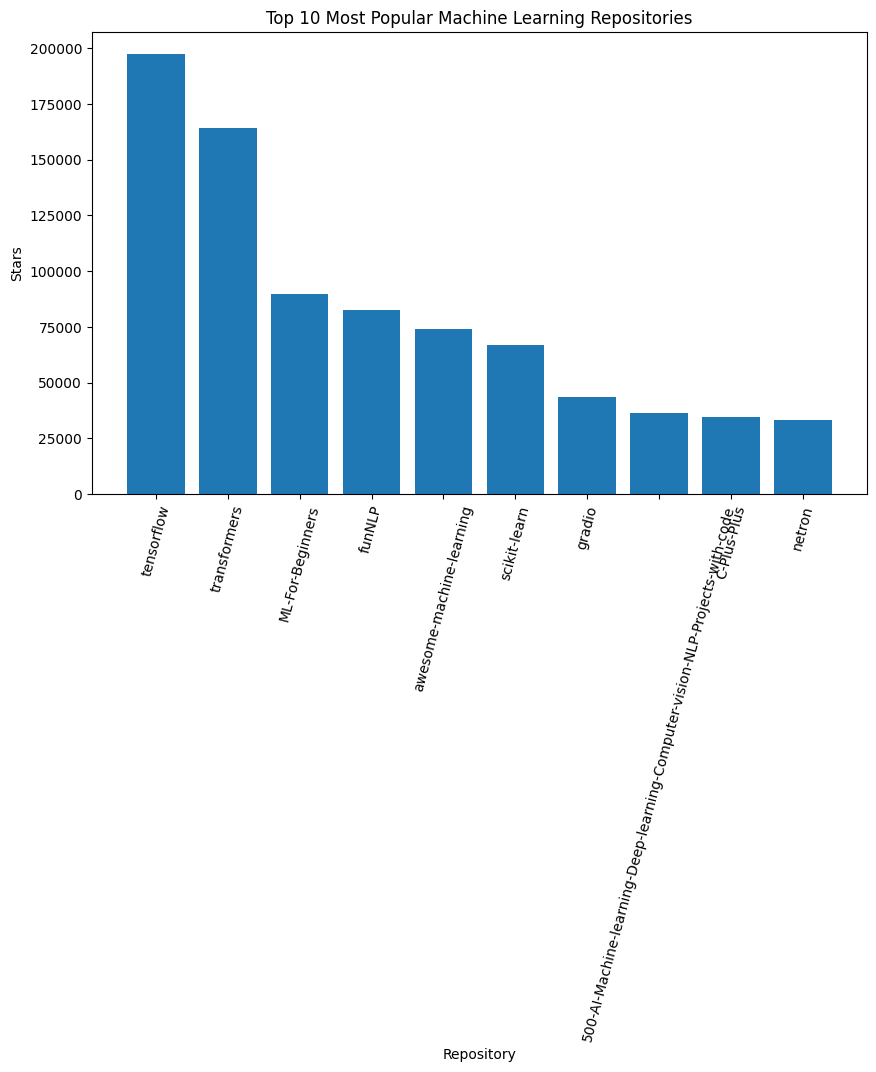

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.bar(top10["name"], top10["stars"])

plt.xticks(rotation=75)
plt.xlabel("Repository")
plt.ylabel("Stars")
plt.title("Top 10 Most Popular Machine Learning Repositories")

plt.tight_layout()
plt.show()

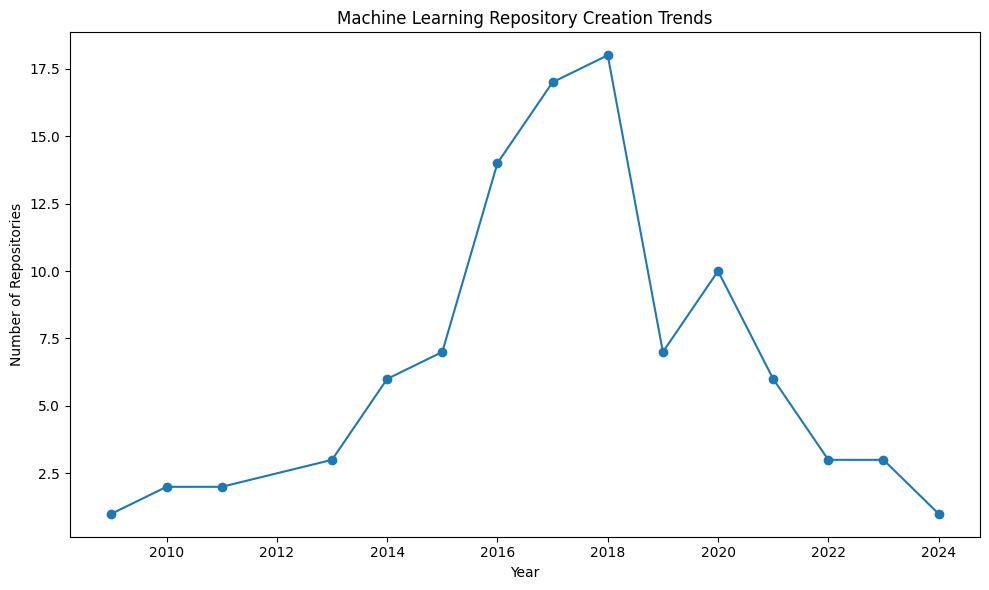

In [ ]:
query = """
SELECT created_date
FROM Repositories;
"""

dates = pd.read_sql_query(query, conn)

dates["created_date"] = pd.to_datetime(dates["created_date"])

yearly_repositories = (
    dates["created_date"]
    .dt.year
    .value_counts()
    .sort_index()
)

plt.figure(figsize=(10, 6))

plt.plot(
    yearly_repositories.index,
    yearly_repositories.values,
    marker="o"
)

plt.xlabel("Year")
plt.ylabel("Number of Repositories")
plt.title("Machine Learning Repository Creation Trends")

plt.tight_layout()
plt.show()

In [ ]:
print("Total repositories:", pd.read_sql_query(
    "SELECT COUNT(*) AS total FROM Repositories", conn
).iloc[0, 0])

print("Average stars:", round(pd.read_sql_query(
    "SELECT AVG(stars) AS average FROM Repositories", conn
).iloc[0, 0], 2))

print("\nTop 10 repositories:")
print(top10)

print("\nRepositories by language:")
print(language_analysis)

Total repositories: 100
Average stars: 20822.05

Top 10 repositories:
                                                name           owner   stars
0                                         tensorflow      tensorflow  197328
1                                       transformers     huggingface  164343
2                                   ML-For-Beginners       microsoft   89685
3                                             funNLP  fighting41love   82599
4                           awesome-machine-learning    josephmisiti   74118
5                                       scikit-learn    scikit-learn   67010
6                                             gradio      gradio-app   43405
7  500-AI-Machine-learning-Deep-learning-Computer...   ashishpatel26   36454
8                                        C-Plus-Plus   TheAlgorithms   34591
9                                             netron      lutzroeder   33387

Repositories by language:
           language  repository_count
0            Pytho

1. Overall dataset:
The dataset contains 100 Machine Learning repositories, with an average of approximately 20,822 stars per repository.

2. Most popular repositories:
The most popular repository is TensorFlow, with 197,328 stars, followed by Transformers with 164,343 stars. This shows that these projects have very high popularity and community interest.

3. Programming languages:
Python is the most common programming language, with 30 repositories, followed by Jupyter Notebook with 19 repositories and C++ with 12 repositories. This suggests that Python is highly represented among the Machine Learning repositories in this dataset.

4. General insight:
The results show that Machine Learning projects on GitHub have strong community interest, as reflected by their high number of stars. Python and Jupyter Notebook are particularly common in the analyzed repositories.